# Top artists per genre

My most played artists inside each of my top genres, using each artist's cleaned tags.

## Load data

Uses `scrobbles.parquet` and `artist_tags.parquet` from the project folder, or `sample_data/` if they aren't there. Tags are cleaned with `clean_tags` from `tags.py`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tags import clean_tags
from viz import BAR_COLOR, SERIES_COLORS, SURFACE, INK, INK_SECONDARY, MUTED, GRID, BASELINE, add_title, save_figure

DATA_DIR = '.' if os.path.exists('scrobbles.parquet') else 'sample_data'  # falls back to the bundled sample
print(f'data: {DATA_DIR}')

df = pd.read_parquet(f'{DATA_DIR}/scrobbles.parquet')
artist_tags = clean_tags(pd.read_parquet(f'{DATA_DIR}/artist_tags.parquet'))
print(df.shape, artist_tags.shape)

data: .
(34036, 5) (4985, 3)


## Plays per artist and primary tag

Every artist has several tags, so each one is assigned to a single genre: its highest-weight tag after cleaning. Ties go to the tag that comes first alphabetically. That way each artist appears once, and the genres add up to all the plays that have a tag. The catch is that a broad tag like `rock` can win over a more specific one, and artists with no tags are left out. `03_genres.ipynb` does it the other way and counts a play under every tag.

In [2]:
TOP_N = 5  # artists to show for each genre
N_GENRES = 9  # how many of the top tags to chart, laid out three to a row

artist_plays = df['artist'].value_counts().rename('plays').rename_axis('artist').reset_index()
primary = (artist_tags.sort_values(['artist', 'weight', 'tag'], ascending=[True, False, True])
                      .groupby('artist').head(1))  # each artist's highest-weight tag; ties go to the first alphabetically
by_tag = primary[['artist', 'tag']].merge(artist_plays, on='artist')  # one row per artist

genres = by_tag.groupby('tag')['plays'].sum().nlargest(N_GENRES).index  # tags with the most plays, counting each artist once
print(genres.tolist())

['hip-hop', 'indie', 'electronic', 'classic rock', 'indie rock', 'jazz', 'folk', 'indie pop', 'rock']


## Top artists for one genre

`top_artists_in` returns the top artists for any tag, so a genre outside the top few can be looked up too. It only includes artists whose primary tag is that one.

In [3]:
def top_artists_in(tag, n=TOP_N):
    '''The n most played artists whose primary tag is `tag`, with their play counts.'''
    return by_tag[by_tag['tag'] == tag].nlargest(n, 'plays')[['artist', 'plays']].reset_index(drop=True)


top_artists_in(genres[0])

,artist,plays
0,MF DOOM,366
1,Kanye West,329
2,The Notorious B.I.G.,231
3,Kendrick Lamar,221
4,Childish Gambino,167


## The figure

One panel per genre, with the artists ranked from most played at the top. Each panel is scaled to its own top artist, so the bars compare artists within a genre and not across genres.

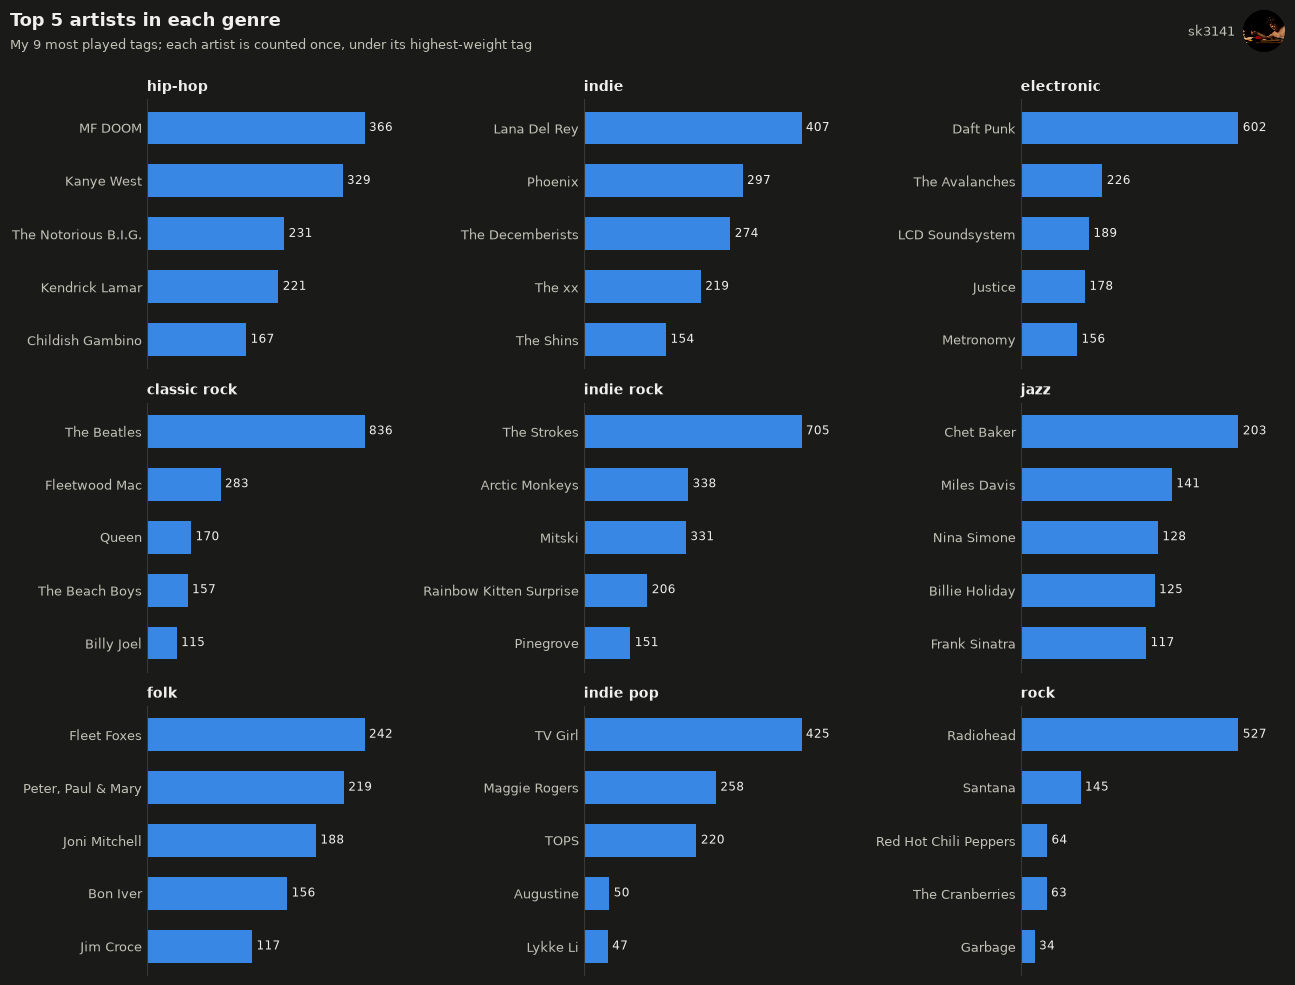

In [4]:
def short_name(name, limit=24):
    return name if len(name) <= limit else name[:limit - 1].rstrip() + '\u2026'


def plot_top_artists_by_genre(save=False):
    '''Small multiples: the top artists in each of the top genres, as horizontal bars.'''
    n_cols = 3
    n_rows = -(-len(genres) // n_cols)  # ceiling division
    row_height = 0.42 * TOP_N + 0.8  # room for the bars and the panel title
    height = row_height * n_rows + 1.2
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(13, height), facecolor=SURFACE, squeeze=False)

    for ax, tag in zip(axes.flat, genres):
        top = top_artists_in(tag)
        ax.set_facecolor(SURFACE)
        positions = range(len(top))
        ax.barh(positions, top['plays'], color=BAR_COLOR, height=0.62)
        ax.set_yticks(positions, [short_name(name) for name in top['artist']])
        ax.invert_yaxis()  # most played on top
        ax.set_xlim(0, top['plays'].max() * 1.2)  # room for the value labels
        for y, plays in zip(positions, top['plays']):
            ax.text(plays + top['plays'].max() * 0.02, y, f'{plays:,}', va='center', fontsize=8.5, color=INK)

        ax.set_title(tag, loc='left', fontsize=10, fontweight='bold', color=INK)
        ax.set_xticks([])
        for side in ('top', 'right', 'bottom'):
            ax.spines[side].set_visible(False)
        ax.spines['left'].set_color(BASELINE)
        ax.tick_params(length=0, labelsize=9, labelcolor=INK_SECONDARY)

    for ax in axes.flat[len(genres):]:
        ax.set_visible(False)  # unused panels

    add_title(fig, f'Top {TOP_N} artists in each genre',
              f'My {len(genres)} most played tags; each artist is counted once, under its highest-weight tag', height)
    fig.tight_layout(rect=(0, 0, 1, 1 - 0.65 / height))
    if save:
        save_figure(fig, 'top_artists_by_genre')
    plt.show()


plot_top_artists_by_genre(save=True)

## Share of plays by genre

With one tag per artist, the genres add up to all of my plays, so they can be shown as shares of a whole. Genres below `MIN_SHARE` of all plays are grouped into `other`, and plays from artists that have no tags go under `no tag`. At most `MAX_GENRES` genres are named.

In [17]:
MIN_SHARE = 0.002  # genres with a smaller share of all plays go into 'other'
MAX_GENRES = 16  # most genres to name; the rest go into 'other' too

genre_plays = by_tag.groupby('tag')['plays'].sum().sort_values(ascending=False)
genre_shares = genre_plays / len(df)  # share of all plays, tagged or not

named = genre_shares[genre_shares >= MIN_SHARE].head(MAX_GENRES)
parts = pd.concat([named, pd.Series({'other': genre_shares.drop(named.index).sum(),
                                      'no tag': 1 - genre_shares.sum()})])
parts = parts[parts > 0]  # skip a group that turned out empty
parts.round(3)

hip-hop              0.119
indie                0.085
electronic           0.078
classic rock         0.077
indie rock           0.075
jazz                 0.049
folk                 0.048
indie pop            0.041
rock                 0.031
rnb                  0.028
soul                 0.025
pop                  0.024
alternative          0.020
trip-hop             0.016
dream pop            0.014
singer-songwriter    0.014
other                0.230
no tag               0.025
dtype: float64

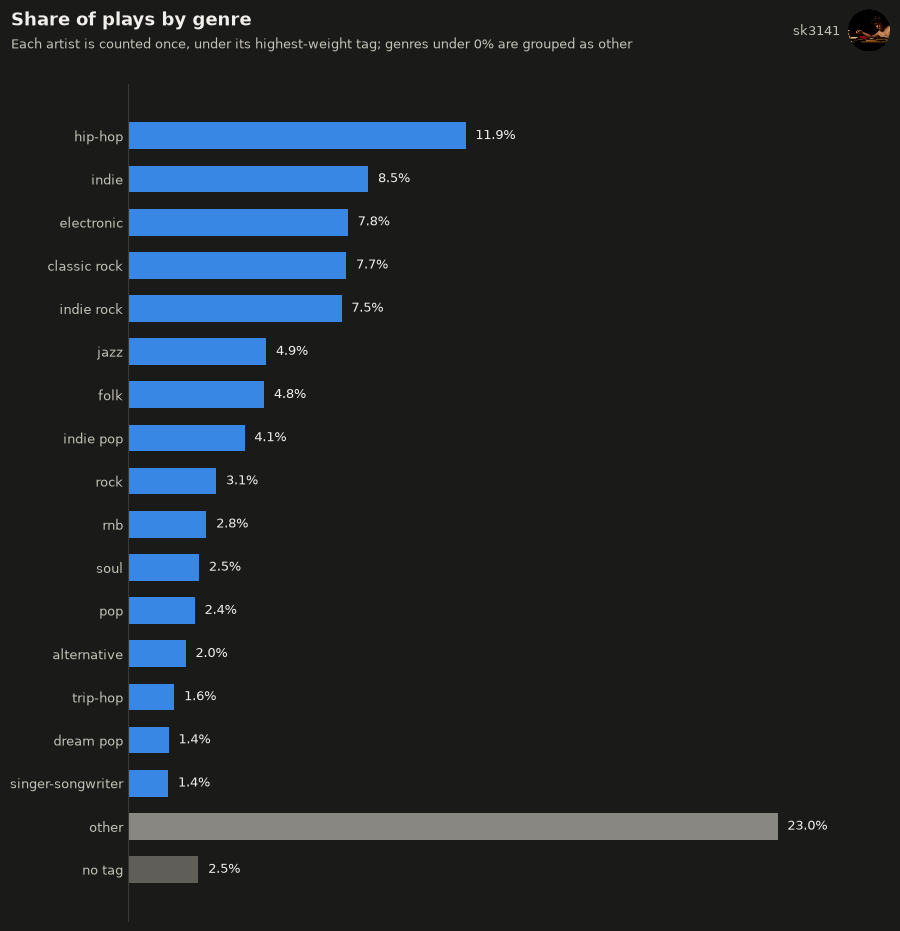

In [18]:
GROUP_COLORS = {'other': MUTED, 'no tag': '#5f5e59'}  # grays for the groups, so they don't look like genres


def style_axes(ax):
    '''No frame except the baseline on the left, and no x axis.'''
    ax.set_facecolor(SURFACE)
    ax.set_xticks([])
    for side in ('top', 'right', 'bottom'):
        ax.spines[side].set_visible(False)
    ax.spines['left'].set_color(BASELINE)
    ax.tick_params(length=0, labelsize=9.5, labelcolor=INK_SECONDARY)


def plot_genre_bars(save=False):
    '''Ranked horizontal bars of each genre's share of all plays.'''
    height = 0.45 * len(parts) + 1.5
    fig, ax = plt.subplots(figsize=(9, height), facecolor=SURFACE)
    positions = range(len(parts))
    colors = [GROUP_COLORS.get(name, BAR_COLOR) for name in parts.index]
    ax.barh(positions, parts.values * 100, color=colors, height=0.62)
    ax.set_yticks(positions, parts.index)
    ax.invert_yaxis()  # largest on top, the groups last
    ax.set_xlim(0, parts.max() * 100 * 1.15)  # room for the value labels
    for y, share in zip(positions, parts.values):
        ax.text(share * 100 + parts.max() * 100 * 0.015, y, f'{share:.1%}', va='center', fontsize=9, color=INK)
    style_axes(ax)

    add_title(fig, 'Share of plays by genre',
              f'Each artist is counted once, under its highest-weight tag; genres under {MIN_SHARE:.0%} are grouped as other', height)
    fig.subplots_adjust(left=0.14, right=0.97, top=1 - 0.85 / height, bottom=0.04)
    if save:
        save_figure(fig, 'plays_by_genre_bars')
    plt.show()


plot_genre_bars(save=True)

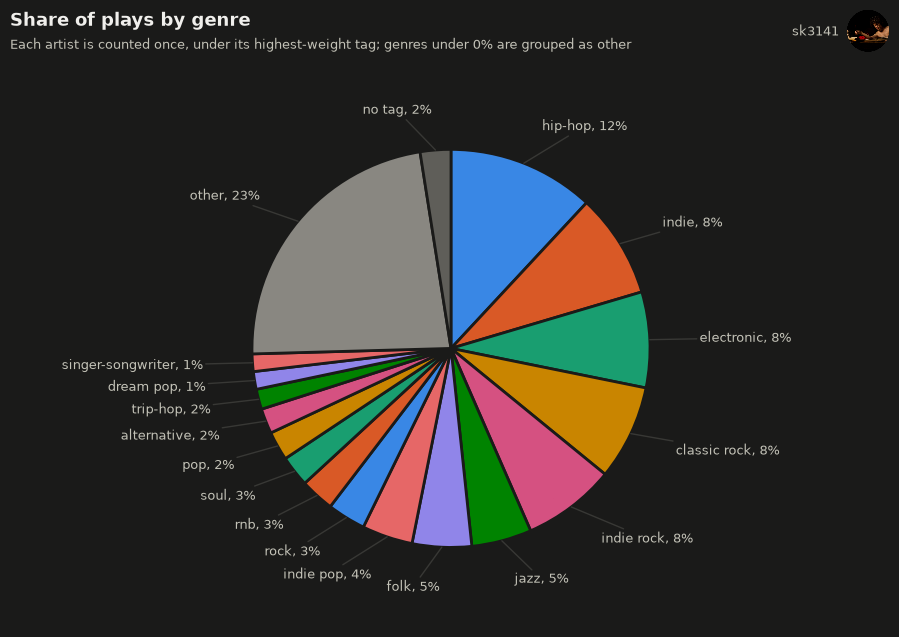

In [19]:
def plot_genre_pie(save=False):
    '''A pie of the same shares, each slice named outside the circle.'''
    height = 6.4
    fig, ax = plt.subplots(figsize=(9, height), facecolor=SURFACE)
    colors = [GROUP_COLORS.get(name, SERIES_COLORS[i % len(SERIES_COLORS)]) for i, name in enumerate(parts.index)]
    wedges, _ = ax.pie(parts.values, colors=colors, startangle=90, counterclock=False,
                       wedgeprops={'edgecolor': SURFACE, 'linewidth': 2})  # surface-colored gap between slices

    for wedge, name, share in zip(wedges, parts.index, parts.values):
        angle = np.deg2rad((wedge.theta1 + wedge.theta2) / 2)  # middle of the slice
        x, y = np.cos(angle), np.sin(angle)
        ax.annotate(f'{name}, {share:.0%}', xy=(x, y), xytext=(1.25 * x, 1.2 * y),
                    ha='left' if x > 0 else 'right', va='center', fontsize=9.5, color=INK_SECONDARY,
                    arrowprops={'arrowstyle': '-', 'color': BASELINE, 'linewidth': 1, 'shrinkA': 0, 'shrinkB': 0})
    ax.set_xlim(-1.9, 1.9)
    ax.set_ylim(-1.4, 1.4)

    add_title(fig, 'Share of plays by genre',
              f'Each artist is counted once, under its highest-weight tag; genres under {MIN_SHARE:.0%} are grouped as other', height)
    fig.subplots_adjust(left=0.02, right=0.98, top=1 - 0.7 / height, bottom=0.02)
    if save:
        save_figure(fig, 'plays_by_genre_pie')
    plt.show()


plot_genre_pie(save=True)